[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D8_descenso_gradiente.ipynb)

# D8 · Descenso de gradiente: regímenes de $\alpha$ y escalamiento

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód III + Mód IV).** Hessiana y sus eigenvalores (curvaturas); estandarizar $x'=(x-\bar x)/s$.

**Supuestos.** Costo cuadrático con hessiana $H$ definida positiva (regresión lineal con $X$ de rango completo), $\alpha$ constante, gradiente exacto.

**La idea.** El error evoluciona como $e_{k+1}=(I-\alpha H)e_k$: en cada dirección propia el factor es $1-\alpha\lambda_j$. Converge si y solo si $\alpha<2/\lambda_{\max}$. El control es $r=\alpha\,\lambda_{\max}$: $r<1$ monótono, $1<r<2$ oscila y converge, $r>2$ diverge.

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
R = 0.8   # r = α · λ_max (el límite es 2)

## La identidad, con números

sin escalar    λ = [0.0666 5.0565]  κ =     75.9  α máx = 2/λ_max = 0.3955
estandarizada  λ = [1. 1.]  κ =      1.0  α máx = 2/λ_max = 2.0000
r = α·λ_max = 0.80  factor 1 − r = +0.20,  monótono


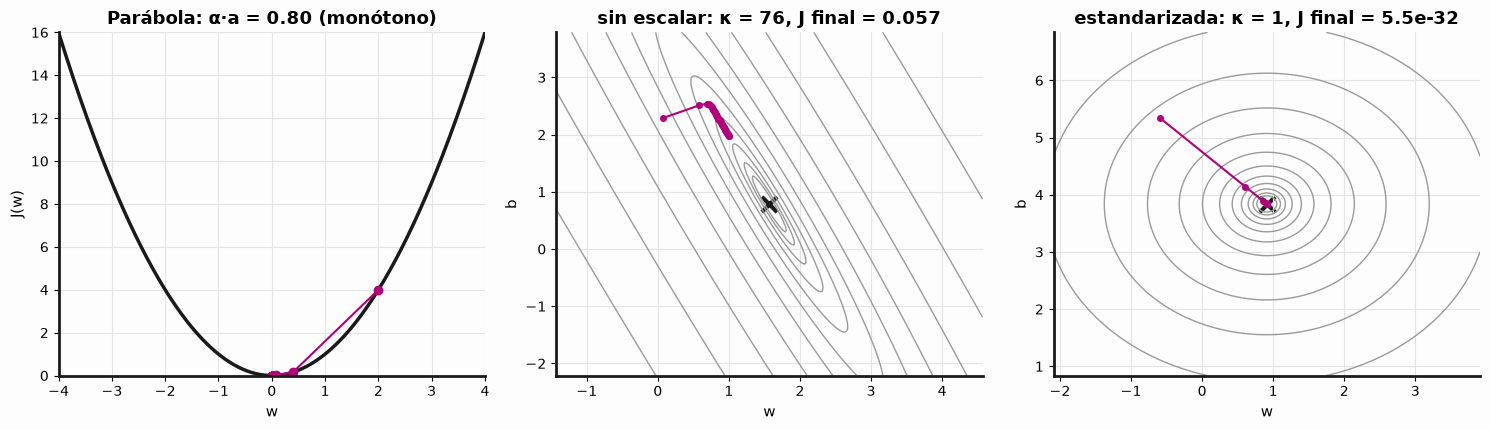

In [3]:
from dammg_utils import CASAS_NG

x = np.array(CASAS_NG["x"]); y = np.array(CASAS_NG["y"]) / 100.0   # x en miles de ft², y en cientos de miles
def hessiana(x):
    Xt = np.column_stack([x, np.ones_like(x)])
    return Xt.T @ Xt / len(x), Xt
xs = (x - x.mean()) / x.std()            # desviación estándar poblacional, así H = I
for nombre, xv in [("sin escalar", x), ("estandarizada", xs)]:
    H, _ = hessiana(xv); ev = np.linalg.eigvalsh(H)
    print(f"{nombre:14s} λ = {ev.round(4)}  κ = {ev.max()/ev.min():8.1f}  α máx = 2/λ_max = {2/ev.max():.4f}")

def trayectoria(xv, r, k=40):
    H, Xt = hessiana(xv)
    lmax = np.linalg.eigvalsh(H).max(); alpha = r / lmax
    th_opt = np.linalg.solve(H, Xt.T @ y / len(y))
    th = th_opt + np.array([-1.5, 1.5]) * [1, 1]   # arranque fijo, relativo al óptimo
    T = [th.copy()]
    for _ in range(k):
        th = th - alpha * (Xt.T @ (Xt @ th - y) / len(y))
        T.append(th.copy())
        if np.abs(th).max() > 1e6: break
    T = np.array(T); E = T - th_opt
    Jk = 0.5 * np.einsum("ki,ij,kj->k", E, H, E)
    return T, th_opt, H, Jk, alpha

MAG = C.get("alpha", "#b0007a")   # α en magenta (docs/notacion.md)

def demo(r=R):
    # 1D: parábola J(w) = (a/2) w²
    a = 2.0; alpha = r / a
    ws = [2.0]
    for _ in range(12):
        ws.append(ws[-1] * (1 - alpha * a))
    ws = np.array(ws)
    regimen = "monótono" if r < 1 - 1e-9 else ("un paso" if np.isclose(r, 1) else ("oscila y converge" if r < 2 - 1e-9 else ("oscila sin converger" if np.isclose(r, 2) else "diverge")))
    print(f"r = α·λ_max = {r:.2f}  factor 1 − r = {1 - r:+.2f},  {regimen}")
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
    g = np.linspace(-4, 4, 300)
    ax[0].plot(g, a / 2 * g**2, color=C["tinta"])
    wv = np.clip(ws, -4, 4)
    ax[0].plot(wv, a / 2 * wv**2, "-o", color=MAG, markersize=6, linewidth=1.5)
    ax[0].set(xlim=(-4, 4), ylim=(0, 16), xlabel="w", ylabel="J(w)", title=f"Parábola: α·a = {r:.2f} ({regimen})")
    # 2D: tazón de la regresión, sin escalar y estandarizada
    for j, (nombre, xv) in enumerate([("sin escalar", x), ("estandarizada", xs)]):
        T, opt, H, Jk, al = trayectoria(xv, r)
        ev = np.linalg.eigvalsh(H)
        W_, B_ = np.meshgrid(np.linspace(opt[0] - 3, opt[0] + 3, 200), np.linspace(opt[1] - 3, opt[1] + 3, 200))
        D = np.stack([W_ - opt[0], B_ - opt[1]], -1)
        Z = 0.5 * np.einsum("...i,ij,...j->...", D, H, D)
        ax[1 + j].contour(W_, B_, Z, levels=np.geomspace(0.01, Z.max(), 12), colors="#9a9a9a", linewidths=1)
        Tc = np.clip(T, opt - 3, opt + 3)
        ax[1 + j].plot(Tc[:, 0], Tc[:, 1], "-o", color=MAG, markersize=4, linewidth=1.5)
        ax[1 + j].scatter(*opt, marker="x", s=120, color=C["tinta"], linewidth=3)
        ax[1 + j].set(xlabel="w", ylabel="b", title=f"{nombre}: κ = {ev.max()/ev.min():.0f}, J final = {Jk[-1]:.2g}")
    fig.tight_layout(); plt.show()

demo()

**¿Qué pasa si…?** Predigan: con $r=1.9$, ¿converge? ¿Cómo se ve el camino? ¿Y con $r=2.1$? ¿Por qué el tazón sin escalar avanza tan lento aunque $r$ sea bueno?

Respuesta esperada: con 1.9 converge zigzagueando; con 2.1 diverge. Sin escalar, $\alpha$ está limitado por la dirección más curva y la dirección plana (con $\lambda_{\min}$ chico) avanza con factor $1-\alpha\lambda_{\min}\approx 1$. Al estandarizar, $\kappa=1$ y todas las direcciones van al mismo ritmo.

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, r=W.FloatSlider(value=R, min=0.1, max=2.2, step=0.05, description='α·λ_max', continuous_update=False))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')